# <span style="color:darkblue"> Lecture 16: Neural Networks and Tensor Flow </span>

<font size = "5">

In this class we will talk about how to set up <br>
a neural network classifier using Tensor Flow

For an introduction

https://www.youtube.com/watch?v=i8NETqtGHms

# <span style="color:darkblue"> I. Setup Working Environment </span>



<font size = "5">

We will be using a new library called "Tensor Flow" that is used <br>
to create neural network architectures

In Windows (Anaconda Prompt) or Mac (Terminal) type:

``` conda install tensorflow ```

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


<font size = "5">

Import tensor flow packages

In [2]:

%pip install tensorflow
# Reinstall a compatible TensorFlow build in the active notebook environment
%pip install --upgrade pip
%pip install --force-reinstall --no-cache-dir "tensorflow-cpu==2.15.0"
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ------------------------------------ --- 2.6/2.9 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------- 2.9/2.9 MB 13.9 MB/s  0:00:00
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 17.1 MB/s  0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------- ----------------------------- 3.4/12.6 MB 16.7 MB/s eta 0:00:01
   ------------------------- -------------- 8.1/12.6 MB 21.0 MB/s eta 0:00:01
   ---------------------------------------  12.6/12.6 MB 21.3 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 17.9 MB/s  0:00:00

  Attempting uninstall: protobuf

    Found existing installation: protobuf 4.25.9

    Uninstalling protobuf-4.25.

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
chromadb 1.0.12 requires httpx>=0.27.0, but you have httpx 0.20.0 which is incompatible.
googleapis-common-protos 1.70.0 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
gradio 5.33.0 requires httpx>=0.24.1, but you have httpx 0.20.0 which is incompatible.
opentelemetry-proto 1.34.0 requires protobuf<6.0,>=5.0, but you have protobuf 7.36.2 which is incompatible.
streamlit 1.45.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.
tensorflow-intel 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.15.1 which is incompatible.
tensorfl

Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/300.9 MB ? eta -:--:--
    --------------------------------------- 4.7/300.9 MB 25.9 MB/s eta 0:00:12
   - -------------------------------------- 10.5/300.9 MB 25.2 MB/s eta 0:00:12
   -- ------------------------------------- 16.3/300.9 MB 26.3 MB/s eta 0:00:11
   -- ------------------------------------- 21.8/300.9 MB 26.0 MB/s eta 0:00:11
   --- ------------------------------------ 27.0/300.9 MB 25.5 MB/s eta 0:00:11
   ---- ----------------------------------- 32.8/300.9 MB 25.7 MB/s eta 0:00:11
   ----- ---------------------------------- 38.8/300.9 MB 26.0 MB/s eta 0:00:11
   ----- ---------------------------------- 44.6/300.9 MB 26.2 MB/s eta 0:00:10
   ------ --------------------------------- 49.8/300.9 MB 26.0 MB/s eta 0:00:10
   ------- -------------------------------- 55.6/300.9 MB 26.0 MB/s eta 0:00:10
   -------- ------------------------------- 61.1/300.9 MB 26.1 MB/s eta 0:00:10
   -------- ------------------------------- 66.1/3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
chromadb 1.0.12 requires httpx>=0.27.0, but you have httpx 0.20.0 which is incompatible.
gradio 5.33.0 requires httpx>=0.24.1, but you have httpx 0.20.0 which is incompatible.
gradio-client 1.10.2 requires httpx>=0.24.1, but you have httpx 0.20.0 which is incompatible.
gradio-client 1.10.2 requires websockets<16.0,>=10.0, but you have websockets 17.2 which is incompatible.
huggingface-hub 1.8.0 requires httpx<1,>=0.23.0, but you have httpx 0.20.0 which is incompatible.
jupyterlab 4.3.6 requires httpx>=0.25.0, but you have httpx 0.20.0 which is incompatible.
langchain-core 0.3.64 requires packaging<25,>=23.2, but you have packaging 26.3 which is incompatible.
langsmith 0.3.45 requires httpx<1,>=0.23.0, but you have httpx 0.20.0 which is incompatible.
openai 1.84.0 requires httpx<1,>=0.23.0, but you have httpx 0.20.

# <span style="color:darkblue"> II. Data </span>

<font size = "5">

Online Shoppers Purchasing Intention Dataset (OSHPID)

- This dataset contains information about user sessions
- It contains features data about user behavior 
while <br> navigating website
- The goal is to predict whether the customer will purchase or not

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset


In [3]:
# Fetch online data from the UC Irvine Machine Learning Repository API
online_shopping= fetch_ucirepo(id=468) 

# Extract
X = online_shopping.data.features
# Drop columns that contain non-numeric values
X = X.drop(columns = ["Month","VisitorType"])

# Extract label data
y = online_shopping.data.targets["Revenue"]


In [4]:
# Convert to float types (avoids issues down the line)
X = np.asarray(X).astype(np.float32)
y = np.asarray(y).astype(np.float32)

<font size = "5">

Pre-process data prior to running model

In [5]:
# Split into training and test
X_train, X_test, y_train, y_test = train_test_split(X,y , 
                                   random_state=104,  
                                   test_size=0.25,  
                                   shuffle=True) 

In [6]:
# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.fit(X_test).transform(X_test)

# <span style="color:darkblue"> III. Training a neural network </span>


<font size = "5">

Define number of features in $X$

In [7]:
k_features = X.shape[1]
print(k_features)

15


<font size = "5">

To define a neural network we start with a configuration setup

- We start with an empty canvas with "Keras"
- Then we successively add how many layers we want <br>
and what type

For more information about Keras layers:

https://www.educative.io/answers/what-are-keras-layers

In [8]:
# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

In [9]:
# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

<font size = "5">

Define an optimizer

In [10]:
# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

In [11]:
# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

<font size = "5">

Estimate model

- The optimization algorithm proceeds sequentially, through epocs
- Set a random seed to ensure reproducibility

In [12]:
# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

Epoch 1/100


289/289 [==============================] - 4s 3ms/step - loss: 5.6137 - accuracy: 0.7655
Epoch 2/100
289/289 [==============================] - 1s 3ms/step - loss: 1.2013 - accuracy: 0.8482
Epoch 3/100
289/289 [==============================] - 1s 3ms/step - loss: 0.9359 - accuracy: 0.8591
Epoch 4/100
289/289 [==============================] - 1s 3ms/step - loss: 0.8318 - accuracy: 0.8602
Epoch 5/100
289/289 [==============================] - 1s 3ms/step - loss: 0.7080 - accuracy: 0.8597
Epoch 6/100
289/289 [==============================] - 1s 3ms/step - loss: 0.8313 - accuracy: 0.8554
Epoch 7/100
289/289 [==============================] - 1s 3ms/step - loss: 0.7060 - accuracy: 0.8557
Epoch 8/100
289/289 [==============================] - 1s 3ms/step - loss: 0.7134 - accuracy: 0.8629
Epoch 9/100
289/289 [==============================] - 1s 3ms/step - loss: 0.8675 - accuracy: 0.8540
Epoch 10/100
289/289 [==============================] - 1s 3ms/step - loss: 0.7456 - accu

# <span style="color:darkblue"> IV. Evaluate a neural network </span>


<font size = "5">

Obtain predicted probabilities and convert them to {0,1}

In [13]:
# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

97/97 [==============================] - 1s 9ms/step


<font size = "5">

Obtain confusion matrix

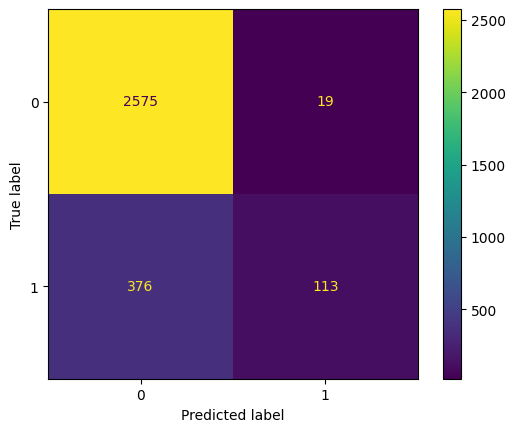

In [14]:
# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()

<font size = "5">

At the moment we defined a very simple neural network <br>
with just an input layer and an output layer. <br>

Try it yourself!

- Increase the number of units in the input layer
- Does prediction accuracy improve?


Test accuracy with 32 units: 0.8910


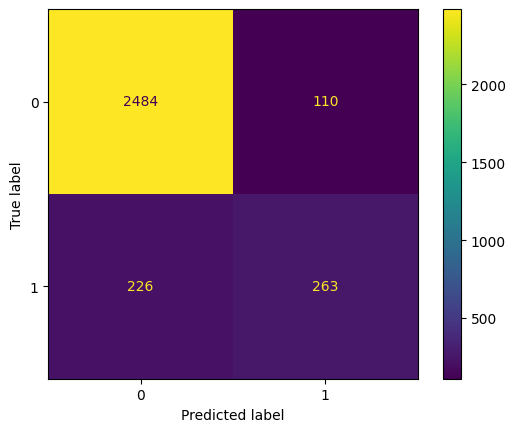

In [18]:
# Increase the number of units in the input (hidden) layer
tf.keras.utils.set_random_seed(0)
larger_model = keras.models.Sequential([
    Dense(units=32, activation="relu", input_shape=(k_features,)),
    Dense(units=1, activation="sigmoid")
])

larger_model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

larger_model.fit(
    X_train_scale,
    y_train,
    epochs=100,
    verbose=0
)

test_loss, test_accuracy = larger_model.evaluate(
    X_test_scale,
    y_test,
    verbose=0
)

print(f"Test accuracy with 32 units: {test_accuracy:.4f}")

predicted_prob_large = tf.squeeze(larger_model.predict(X_test_scale, verbose=0))
predicted_large = (predicted_prob_large >= 0.5).numpy().astype(int)

cm_large = confusion_matrix(y_test, predicted_large)
ConfusionMatrixDisplay(confusion_matrix=cm_large).plot()


<font size = "5">


Try it yourself!

- Add one or more hidden layers
- Does prediction accuracy improve?

Test accuracy with two hidden layers: 0.8891
Test accuracy with one 32-unit layer: 0.8910


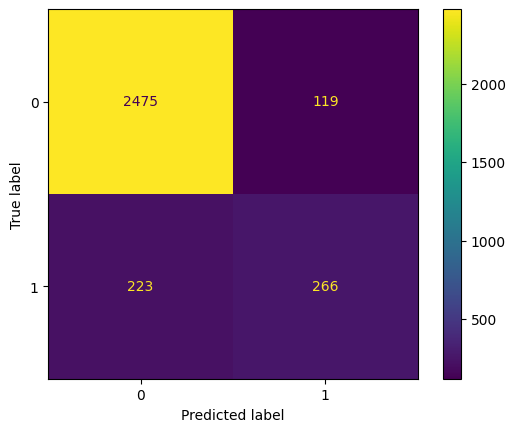

In [19]:
# Define a model with two hidden layers
tf.keras.utils.set_random_seed(0)

hidden_model = keras.models.Sequential([
    Dense(units=32, activation="relu", input_shape=(k_features,)),
    Dense(units=16, activation="relu"),
    Dense(units=1, activation="sigmoid")
])

hidden_model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

hidden_model.fit(
    X_train_scale,
    y_train,
    epochs=100,
    verbose=0
)

hidden_loss, hidden_accuracy = hidden_model.evaluate(
    X_test_scale,
    y_test,
    verbose=0
)

print(f"Test accuracy with two hidden layers: {hidden_accuracy:.4f}")
print(f"Test accuracy with one 32-unit layer: {test_accuracy:.4f}")

predicted_prob_hidden = tf.squeeze(
    hidden_model.predict(X_test_scale, verbose=0)
)
predicted_hidden = (predicted_prob_hidden >= 0.5).numpy().astype(int)

cm_hidden = confusion_matrix(y_test, predicted_hidden)
ConfusionMatrixDisplay(confusion_matrix=cm_hidden).plot()



<font size = "5">

Try it yourself!

- Import the Mashable dataset that we used earlier <br>
(you can find this in this in the ```ArticlesTrain.csv``` and <br>
```ArticlesTest.csv``` files in the ```data_raw``` folder)

- Try to set up a neural network with a simple input-output layer 

In [20]:
from pathlib import Path

# Write your own code


# Load the Mashable article data
train_path = Path("data_raw/ArticlesTrain.csv")
test_path = Path("data_raw/ArticlesTest.csv")

articles_train = pd.read_csv(train_path)
articles_test = pd.read_csv(test_path)

# Predict the continuous "shares" outcome
target_col = next(
    (col for col in articles_train.columns if col.lower() == "shares"),
    None
)
if target_col is None:
    raise ValueError("Could not find a 'shares' target column in ArticlesTrain.csv.")

# Use numeric columns as features; exclude the target
feature_cols = articles_train.drop(columns=target_col).select_dtypes(
    include=np.number
).columns

X_articles = articles_train[feature_cols].replace([np.inf, -np.inf], np.nan)
X_articles_test = (
    articles_test.reindex(columns=feature_cols)
    .replace([np.inf, -np.inf], np.nan)
)

# Fill missing feature values using training-data medians
feature_medians = X_articles.median()
X_articles = X_articles.fillna(feature_medians)
X_articles_test = X_articles_test.fillna(feature_medians)

# Log-transform shares to reduce the effect of its skewed distribution
y_articles = np.log1p(articles_train[target_col].astype(np.float32))

X_train_articles, X_val_articles, y_train_articles, y_val_articles = train_test_split(
    X_articles.to_numpy(dtype=np.float32),
    y_articles.to_numpy(dtype=np.float32),
    test_size=0.2,
    random_state=0
)

# Fit scaling on the training portion only
articles_scaler = preprocessing.StandardScaler().fit(X_train_articles)
X_train_articles = articles_scaler.transform(X_train_articles)
X_val_articles = articles_scaler.transform(X_val_articles)

# Simple input-to-output network (no hidden layer)
tf.keras.utils.set_random_seed(0)
articles_model = keras.models.Sequential([
    Dense(1, input_shape=(X_train_articles.shape[1],), activation="linear")
])

articles_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
articles_model.fit(
    X_train_articles,
    y_train_articles,
    validation_data=(X_val_articles, y_val_articles),
    epochs=50,
    verbose=1
)

# Predict shares for ArticlesTest.csv
X_articles_test_scaled = articles_scaler.transform(
    X_articles_test.to_numpy(dtype=np.float32)
)
predicted_log_shares = articles_model.predict(X_articles_test_scaled, verbose=0).ravel()
predicted_shares = np.expm1(predicted_log_shares).clip(min=0)

print(f"Validation loss (log-share MSE): {articles_model.evaluate(X_val_articles, y_val_articles, verbose=0)[0]:.4f}")
print("Predicted shares for the first five test articles:", predicted_shares[:5])




Epoch 1/50
125/125 [==============================] - 1s 5ms/step - loss: 5.6081 - mae: 2.1073 - val_loss: 4.7412 - val_mae: 1.9715
Epoch 2/50
125/125 [==============================] - 0s 2ms/step - loss: 4.4295 - mae: 1.9540 - val_loss: 3.8790 - val_mae: 1.8512
Epoch 3/50
125/125 [==============================] - 0s 2ms/step - loss: 3.6927 - mae: 1.8324 - val_loss: 3.2965 - val_mae: 1.7425
Epoch 4/50
125/125 [==============================] - 0s 2ms/step - loss: 3.1564 - mae: 1.7190 - val_loss: 2.8450 - val_mae: 1.6357
Epoch 5/50
125/125 [==============================] - 0s 2ms/step - loss: 2.7228 - mae: 1.6071 - val_loss: 2.4617 - val_mae: 1.5304
Epoch 6/50
125/125 [==============================] - 0s 2ms/step - loss: 2.3517 - mae: 1.4999 - val_loss: 2.1284 - val_mae: 1.4280
Epoch 7/50
125/125 [==============================] - 0s 2ms/step - loss: 2.0308 - mae: 1.3965 - val_loss: 1.8346 - val_mae: 1.3285
Epoch 8/50
125/125 [==============================] - 0s 2ms/step - loss: 1

# <span style="color:darkblue"> V. Additional resources </span>

<font size = "5">

Quick guide:

https://www.tensorflow.org/tutorials/quickstart/beginner

Binary classification:

https://www.freecodecamp.org/news/binary-classification-made-simple-with-tensorflow/

Image classification:

https://www.tensorflow.org/tutorials/images/classification

